In [1]:
from simulation import NanobotSimulator 
from diseases import DiseaseSimulator
from plots import AnomalyVisualizer
from drift_detection import AnomalyDetector

In [2]:
sim = NanobotSimulator(alpha=0.3, beta=0.1)

final_report_ph = sim.run_energy_simulation(
    param="ph", 
    mode="zone", 
    is_timeseries=True
)

if final_report_ph is not None and not final_report_ph.empty:
    print(final_report_ph.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_Val  Count  Binomial_%
         1             905.0     9        7.40    131   99.879283
         1             905.0    10        7.37     74   98.834219
         1             905.0    20        7.37    154   99.947698
         1             905.0     3        7.37    100   99.584317
         1             905.0     2        7.39    124   99.835971
         1             905.0     1        7.40    280   99.999513
         1             905.0     4        7.39    174   99.975378
         1             905.0     6        7.40     51   97.119753
         1             905.0     7        7.37     45   96.284365
         1             905.0     8        7.37     51   97.119753
         1             905.0    13        7.37     20   87.870867
         1             905.0    12        7.38     16   85.128305
         1             905.0    16        7.36      5   73.298778
         1             905.0    14        7.37     14   83.459957
         1

In [3]:
sim = NanobotSimulator(alpha=0.3, beta=0.01)

final_report_temp = sim.run_energy_simulation(
    param="temp", 
    mode="zone", 
    is_timeseries=True
)

if final_report_temp is not None and not final_report_temp.empty:
    print(final_report_temp.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_Val  Count  Binomial_%
         1             659.0     9      36.973     93   99.994865
         1             659.0    10      36.886     69   99.959417
         1             659.0    20      36.882    128   99.999713
         1             659.0     3      36.906     85   99.989810
         1             659.0     2      36.956     73   99.971320
         1             659.0     1      37.008    201   99.999999
         1             659.0     4      36.966    133   99.999827
         1             659.0     6      37.044     31   98.792540
         1             659.0     5      36.948     13   93.012181
         1             659.0     7      36.987     30   98.544631
         1             659.0     8      36.789     33   98.996918
         1             659.0    12      37.020      8   86.470725
         1             659.0    14      37.375      5   82.753643
         1             659.0    19      36.402      9   89.238570
         1

In [4]:
sim = NanobotSimulator(alpha=0.3, beta=0.1)

final_report_combined = sim.run_combined_energy_ts(mode='zone')

if final_report_combined is not None and not final_report_combined.empty:
    print(final_report_combined.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_pH  Median_Temp  Count  Binomial_%
         1            1154.0     9       7.39       36.993    164   99.964141
         1            1154.0    10       7.37       36.898     91   99.430905
         1            1154.0    20       7.37       36.882    188   99.985423
         1            1154.0     3       7.37       36.906    139   99.911035
         1            1154.0     2       7.41       36.976    145   99.929179
         1            1154.0     1       7.40       37.004    360   99.999974
         1            1154.0     4       7.40       36.982    229   99.996938
         1            1154.0     6       7.42       37.058     50   96.866074
         1            1154.0     5       7.40       36.979     30   92.465760
         1            1154.0     7       7.38       36.964     56   97.564028
         1            1154.0    13       7.37       37.096     17   86.586649
         1            1154.0     8       7.37       36.786     7

--- 1. Running Disease Simulation (Stroke in Zone 7) ---
[STROKE_PH] Safe Start Applied. Random Onset: Hour 8.6 | Peak: Hour 16.6

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 8.64
Raw Stream: Flagged at Hour 10.53
   -> Delay: 113.3 minutes after onset.
Aggregated Stream: Flagged at Hour 13.60
   -> Delay: 297.4 minutes after onset.

--- 3. Generating Visualization ---


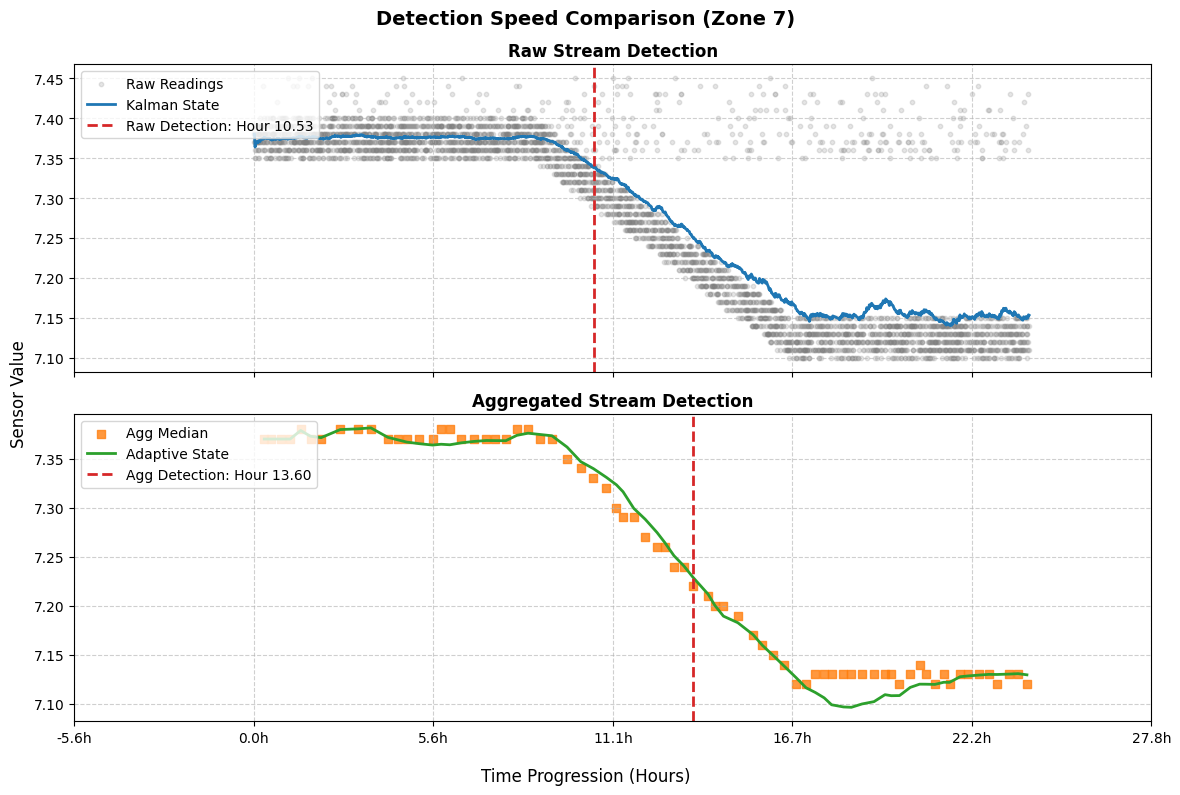

In [ ]:
# 1. Initialize Parameters
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 1800       # 30 minutes. Set to 86400 to simulate a completely healthy patient

print(f"--- 1. Running Disease Simulation (Stroke in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.10
    )

    processed_raw_df, det_raw = detector.detect_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    # Calculate Delay for Raw Stream
    if det_raw:
        delay_raw = det_raw - t_start
        print(f"Raw Stream: Flagged at Hour {det_raw/3600:.2f}")
        if delay_raw < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_raw/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_raw/60:.1f} minutes after onset.")
    else:
        print("Raw Stream: No anomaly detected.")
        
    # Calculate Delay for Aggregated Stream
    if det_agg:
        delay_agg = det_agg - t_start
        print(f"Aggregated Stream: Flagged at Hour {det_agg/3600:.2f}")
        if delay_agg < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_agg/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_agg/60:.1f} minutes after onset.")
    else:
        print("Aggregated Stream: No anomaly detected.")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Detection Speed Comparison (Zone {TARGET_ZONE})"
    )

--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone 16) ---
[PYELO_COMBINED] Safe Start Applied. Random Onset: Hour 12.4 | Peak: Hour 20.4

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 12.36

[AGGREGATED STREAM]
pH   Flagged at Hour 17.37 | Delay: 300.8 min
Temp Flagged at Hour 16.46 | Delay: 246.2 min

--- 3. Generating Visualization ---


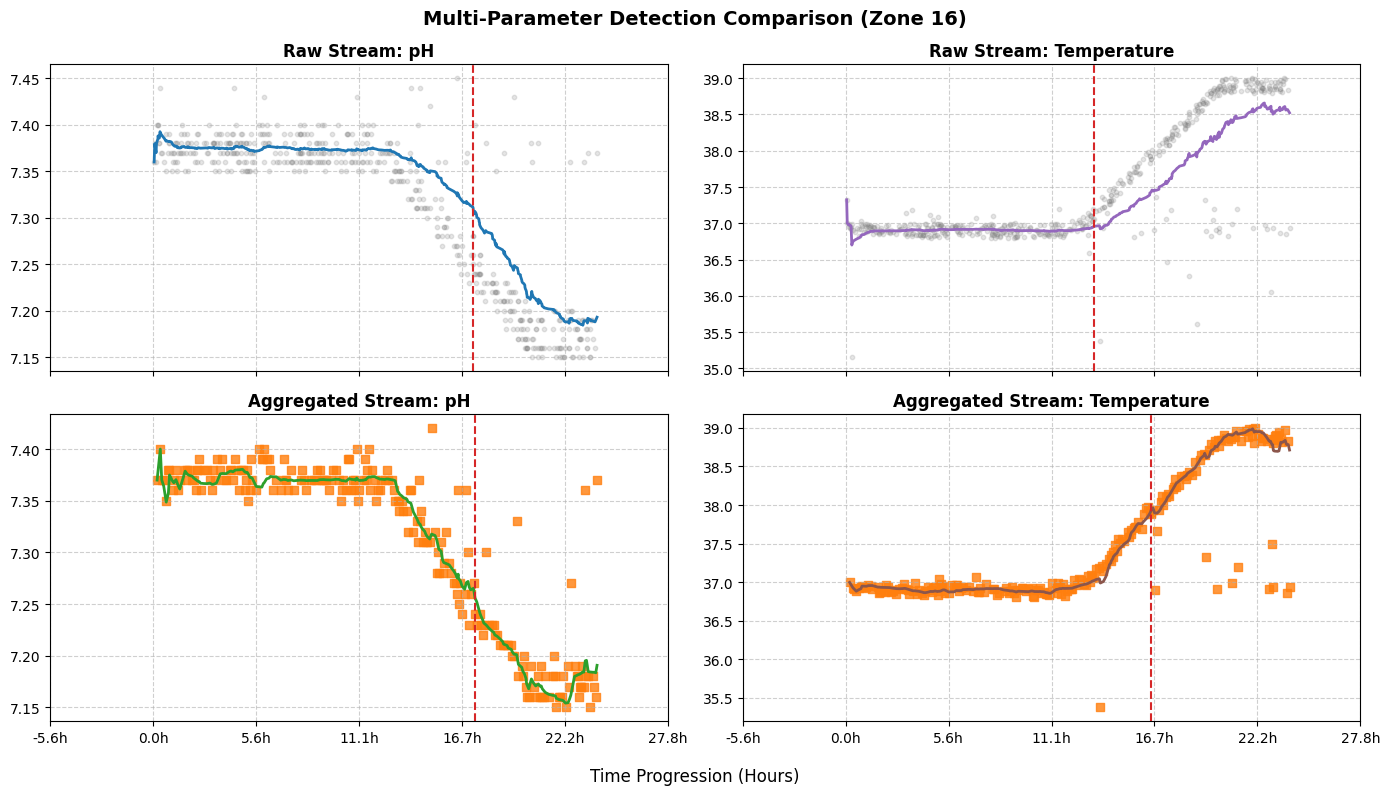

In [ ]:
# 1. Initialize Parameters
TARGET_ZONE = 16         
ALPHA_NOISE = 0.05
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 14400       

print(f"--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_combined_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='pyelo_combined',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        agg_persistence=4,            # Require 4 bad packets in a row
        agg_abs_drift_ph=0.10,        # pH must deviate by at least 0.10
        agg_abs_drift_temp=0.8        # Temp must deviate by at least 0.8 degrees
    )

    processed_raw_df, det_raw = detector.detect_combined_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_combined_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_delay(param_name, det_time, t_start):
        if det_time:
            delay = det_time - t_start
            print(f"{param_name} Flagged at Hour {det_time/3600:.2f}", end=" | ")
            if delay < 0:
                print(f"False Positive ({-delay/60:.1f} min early)")
            else:
                print(f"Delay: {delay/60:.1f} min")
        else:
            print(f"{param_name} No anomaly detected.")
    
    print("\n[AGGREGATED STREAM]")
    print_delay("pH  ", det_agg['ph'], t_start)
    print_delay("Temp", det_agg['temp'], t_start)

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_combined_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Multi-Parameter Detection Comparison (Zone {TARGET_ZONE})"
    )

--- 1. Running Disease Simulation (Stroke in Zone 7) ---
[STROKE_PH] Safe Start Applied. Random Onset: Hour 24.0 | Peak: Hour 32.0

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 24.00
Raw Stream: No anomaly detected.
Aggregated Stream: No anomaly detected.

--- 3. Generating Visualization ---


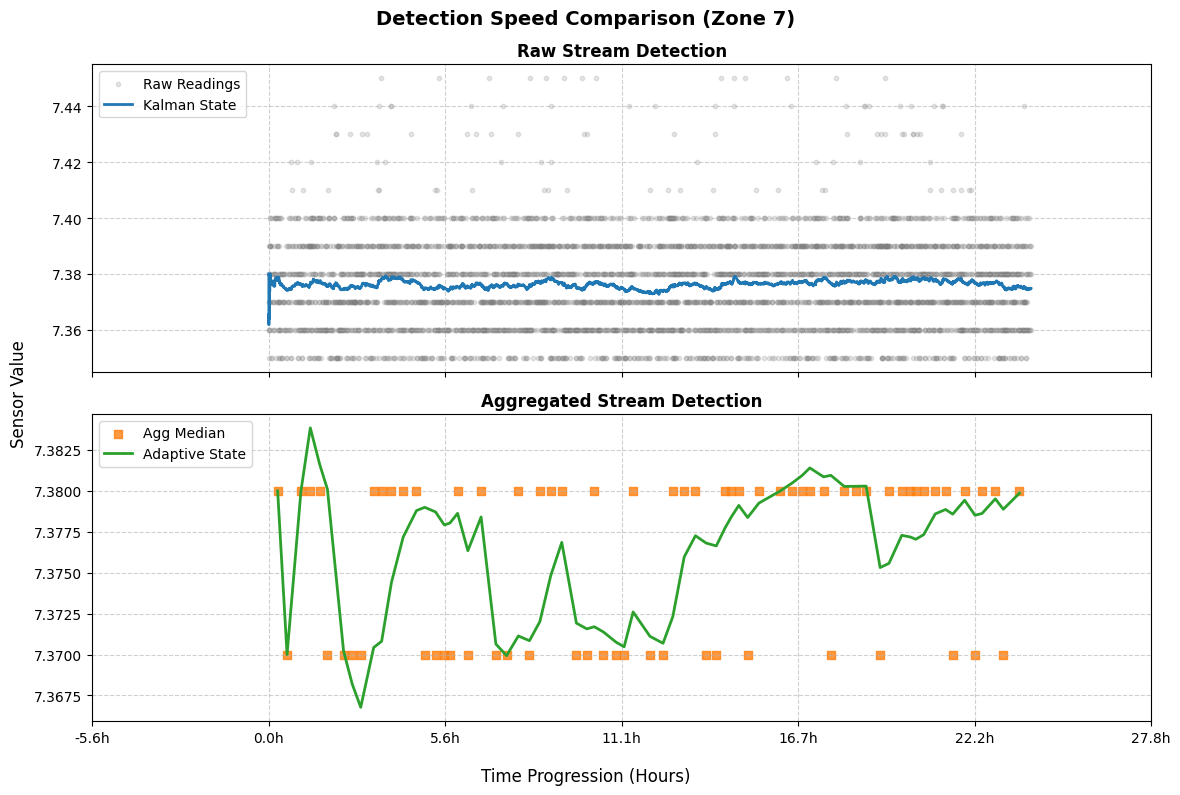

In [ ]:
# 1. Initialize Parameters
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 86400       # Set to 86400 to simulate a completely healthy patient

print(f"--- 1. Running Disease Simulation (Stroke in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF
    )

    processed_raw_df, det_raw = detector.detect_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    # Calculate Delay for Raw Stream
    if det_raw:
        delay_raw = det_raw - t_start
        print(f"Raw Stream: Flagged at Hour {det_raw/3600:.2f}")
        if delay_raw < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_raw/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_raw/60:.1f} minutes after onset.")
    else:
        print("Raw Stream: No anomaly detected.")
        
    # Calculate Delay for Aggregated Stream
    if det_agg:
        delay_agg = det_agg - t_start
        print(f"Aggregated Stream: Flagged at Hour {det_agg/3600:.2f}")
        if delay_agg < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_agg/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_agg/60:.1f} minutes after onset.")
    else:
        print("Aggregated Stream: No anomaly detected.")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Detection Speed Comparison (Zone {TARGET_ZONE})"
    )